In [2]:
def leapfrog(x, v, h, wp=1):
    v_new = v - h * (wp**2) * x
    x_new = x + h * v_new
    return x_new, v_new


In [4]:
import numpy as np
h = 0.1
t_end = 20
wp = 1
n = int(t_end / h)

time_x = np.arange(n + 1) * h
time_v = time_x[:-1] + h / 2

x0 = 0.5
v0 = 0.0

acc0 = -(wp**2) * x0
v = v0 - 0.5 * h * acc0
x = x0

x_num = np.zeros(n + 1)
v_num = np.zeros(n)

x_num[0] = x0

for j in range(n):
    x, v = leapfrog(x, v, h, wp)
    x_num[j + 1] = x
    v_num[j] = v

x_exact = 0.5 * np.cos(time_x)
v_exact = -0.5 * np.sin(time_v)

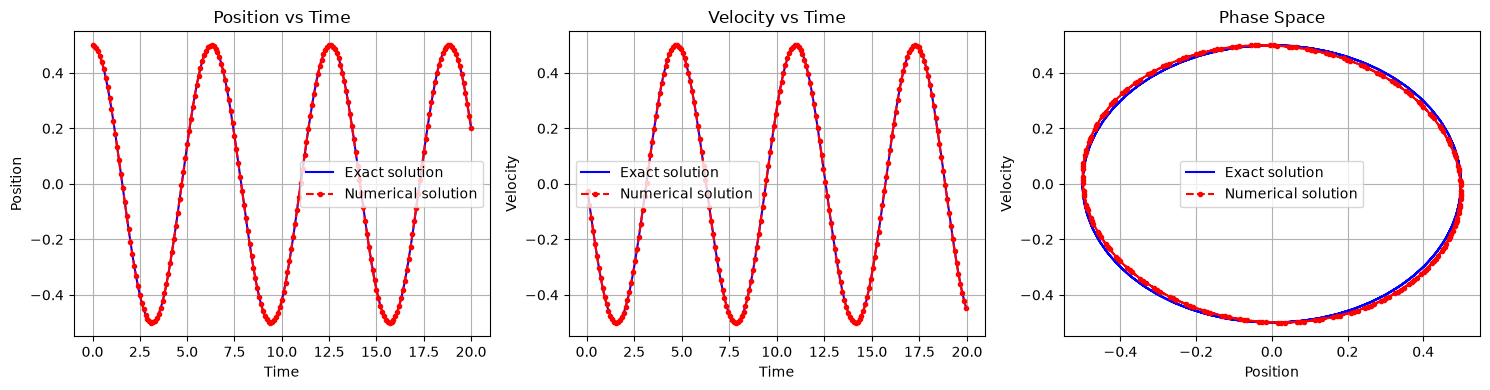

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(time_x, x_exact, 'b-', label='Exact solution')
ax[0].plot(time_x, x_num, 'r--o', markersize=3, label='Numerical solution')
ax[0].set(xlabel='Time', ylabel='Position', title='Position vs Time')
ax[0].legend()
ax[0].grid()

ax[1].plot(time_v, v_exact, 'b-', label='Exact solution')
ax[1].plot(time_v, v_num, 'r--o', markersize=3, label='Numerical solution')
ax[1].set(xlabel='Time', ylabel='Velocity', title='Velocity vs Time')
ax[1].legend()
ax[1].grid()

ax[2].plot(x_exact[:-1], -0.5 * np.sin(time_x[:-1]), 'b-', label='Exact solution')
ax[2].plot(x_num[:-1], v_num, 'r--o', markersize=3, label='Numerical solution')
ax[2].set(xlabel='Position', ylabel='Velocity', title='Phase Space')
ax[2].legend()
ax[2].grid()

plt.tight_layout()
plt.show()

In [7]:
h_values = [0.2, 0.1, 0.05, 0.025]

error_stag = []
error_unstag = []

for staggered in [True, False]:

    errors = []

    for step in h_values:

        t_end = 20
        wp = 1
        N = int(t_end / step)

        time = np.arange(N + 1) * step

        x = 0.5
        v = 0.0

        if staggered:
            a = -(wp**2) * x
            v = v - 0.5 * step * a

        position = np.zeros(N + 1)
        velocity = np.zeros(N)

        position[0] = x

        for k in range(N):
            x, v = leapfrog(x, v, step, wp)
            position[k + 1] = x
            velocity[k] = v

        exact = 0.5 * np.cos(time)
        error = np.max(np.abs(position - exact))

        errors.append(error)

    if staggered:
        error_stag = errors
    else:
        error_unstag = errors


def print_errors(title, errors):

    print("\n" + title)
    print(f"{'Step size':<12} {'Maximum error':<20} {'Order':<10}")
    print("-" * 45)

    for i, step in enumerate(h_values):

        if i == 0:
            print(f"{step:<12} {errors[i]:<20.10f} {'-':<10}")
        else:
            order = np.log(errors[i-1] / errors[i]) / np.log(2)

            print(f"{step:<12} {errors[i]:<20.10f} {order:<10.4f}")


print_errors("STAGGERED INITIALIZATION", error_stag)
print_errors("UNSTAGGERED INITIALIZATION", error_unstag)


STAGGERED INITIALIZATION
Step size    Maximum error        Order     
---------------------------------------------
0.2          0.0153961535         -         
0.1          0.0038152809         2.0127    
0.05         0.0009516946         2.0032    
0.025        0.0002377905         2.0008    

UNSTAGGERED INITIALIZATION
Step size    Maximum error        Order     
---------------------------------------------
0.2          0.0645570937         -         
0.1          0.0286282800         1.1731    
0.05         0.0134016627         1.0950    
0.025        0.0064754034         1.0494    
